In [10]:
import sys, os
import math
import numpy as np
import xarray as xr
import pandas as pd
import rasterio
import rasterio.mask
import geopandas as gpd
import scipy.stats

import contextily as cx
import geopy
import geopy.distance

from shapely.geometry import Point
from shapely.geometry.polygon import Polygon

from pyproj import Transformer
from shapely.ops import transform

from  matplotlib import pyplot as plt

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

def point_buffer1(lat: float, lon: float, radius: int):
    """
    Get the circle or square around a point with a given radius/length in meters.
    """
    standard_crs = "EPSG:4326"

    # Azimuthal equidistant projection
    aeqd_proj = "+proj=aeqd +lat_0={lat} +lon_0={lon} +x_0=0 +y_0=0"

    transformer = Transformer.from_proj(aeqd_proj.format(lat=lat, lon=lon), standard_crs, always_xy=True)

    buffer = Point(0, 0).buffer(radius)

    return transform(transformer.transform, buffer)

def calculate_initial_compass_bearing(pointA, pointB):
    """
    Calculates the bearing between two points.
    The formulae used is the following:
        θ = atan2(sin(Δlong).cos(lat2),
                  cos(lat1).sin(lat2) − sin(lat1).cos(lat2).cos(Δlong))
    :Parameters:
      - `pointA: The tuple representing the latitude/longitude for the
        first point. Latitude and longitude must be in decimal degrees
      - `pointB: The tuple representing the latitude/longitude for the
        second point. Latitude and longitude must be in decimal degrees
    :Returns:
      The bearing in degrees
    :Returns Type:
      float
    """
    if (type(pointA) != tuple) or (type(pointB) != tuple):
        raise TypeError("Only tuples are supported as arguments")

    lat1 = math.radians(pointA[0])
    lat2 = math.radians(pointB[0])

    diffLong = math.radians(pointB[1] - pointA[1])

    x = math.sin(diffLong) * math.cos(lat2)
    y = math.cos(lat1) * math.sin(lat2) - (math.sin(lat1)
            * math.cos(lat2) * math.cos(diffLong))

    initial_bearing = math.atan2(x, y)

    # Now we have the initial bearing but math.atan2 return values
    # from -180° to + 180° which is not what we want for a compass bearing
    # The solution is to normalize the initial bearing as shown below
    initial_bearing = math.degrees(initial_bearing)
    compass_bearing = (initial_bearing + 360) % 360

    return compass_bearing

def get_subarray_coords_rio (arr_shape, src, trs, dest_crs = 4326):
    height = arr_shape[0]
    width = arr_shape[1]

    cols, rows = np.meshgrid(np.arange(width), np.arange(height))
    xs, ys = rasterio.transform.xy(trs, rows, cols)

    xs = np.array(xs)
    ys = np.array(ys)

    trs_wgs = Transformer.from_crs (src.crs, dest_crs)
    lats, lons = trs_wgs.transform(xs,ys)
    return lats, lons


In [11]:
metadata_path = r"D:\!Work\IFA\!data\Urban_fluxes_NE\processed\sitedata_basic.csv"

sites_df = pd.read_csv(metadata_path, sep = ';')

sites_df['latitude'] = sites_df['latitude'].apply(pd.to_numeric, errors='coerce')
sites_df['longitude'] = sites_df['longitude'].apply(pd.to_numeric, errors='coerce')
sites_df

,city_name,site_name,longitude,latitude,time_belt,obs_levels
0,Moscow,MSU,37.522814,55.707187,3.0,"2,11,19"
1,Moscow,ZNS,36.775278,55.696111,3.0,"10,56"
2,Moscow,LOD,37.556350,55.818050,3.0,31
3,Tomsk,IMCES,85.054185,56.474956,7.0,"30,40"
4,Tomsk,Oblkom,84.957451,56.467183,7.0,30
5,Tomsk,BEK,85.101526,56.480872,7.0,30
6,Tomsk,Voronino,85.256111,56.557778,7.0,10
7,Beijing,IAP,116.371285,39.974304,8.0,"8,16,47,80,140,200,280"
8,Beijing,Xianghe,116.960451,39.753441,8.0,"32,80"
9,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
#raster_path = r"G:\! Data\! Global data sets\ESA_Worldcover_joined\urban_fraction_100m.tif"

raster_paths = {'WorldCover':{'Moscow':r"G:\!Data\! Global data sets\ESA_Worldcover_global\ESA_WorldCover_10m_2021_v200_60deg_macrotile_N30E000\ESA_WorldCover_10m_2021_V200_N54E036_Map.tif",
                             'Tomsk':r"G:\!Data\! Global data sets\ESA_Worldcover_global\ESA_WorldCover_10m_2021_v200_60deg_macrotile_N30E060\ESA_WorldCover_10m_2021_v200_N54E084_Map.tif",
                             'Beijing':r"G:\!Data\! Global data sets\ESA_Worldcover_global\ESA_WorldCover_10m_2021_v200_60deg_macrotile_N30E060\ESA_WorldCover_10m_2021_v200_N39E114_Map.tif"},
                'CGLC':r"G:\!Data\! Global data sets\CGLC_global\2019\PROBAV_LC100_global_v3.0.1_2019-nrt_BuiltUp-CoverFraction-layer_EPSG-4326.tif",
                'LCZ':r"G:\!Data\! Global data sets\Global LCZ map\lcz_filter_v1.tif"}
                

C:\Users\mvar9\AppData\Local\Temp\ipykernel_19764\1959845798.py:38: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize = (4,4))


KeyError: nan

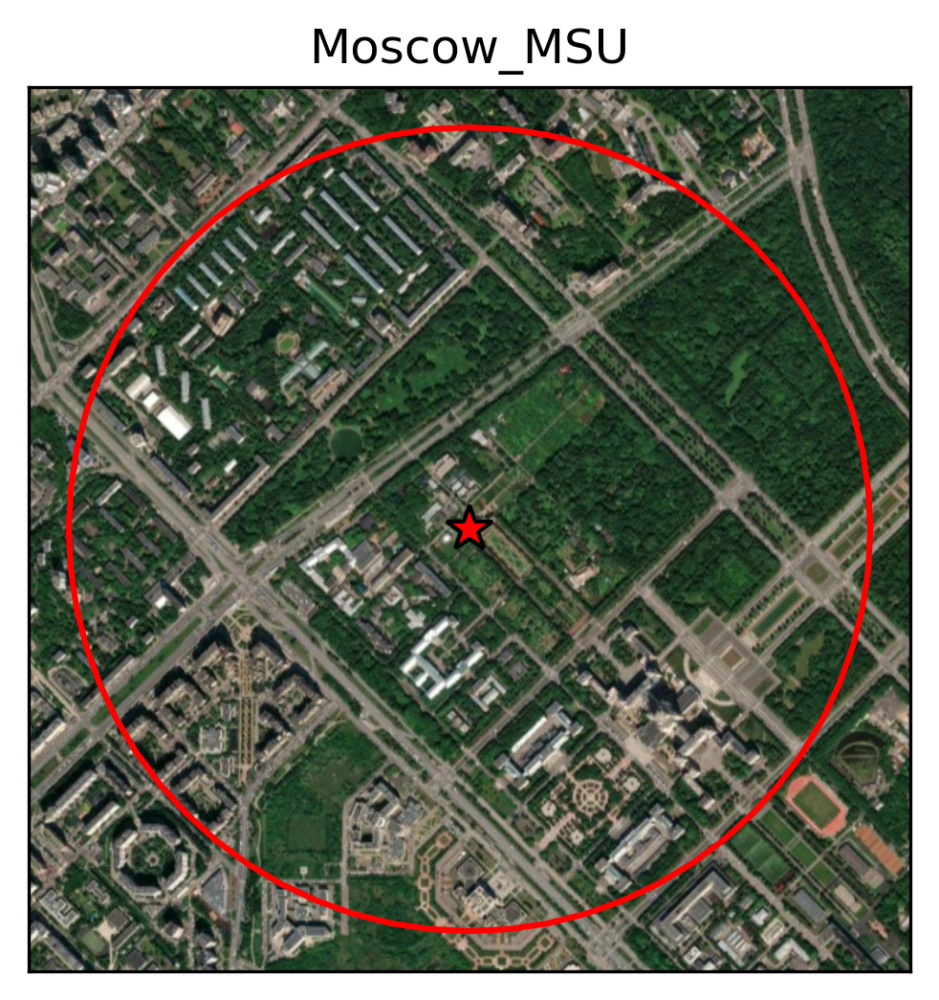

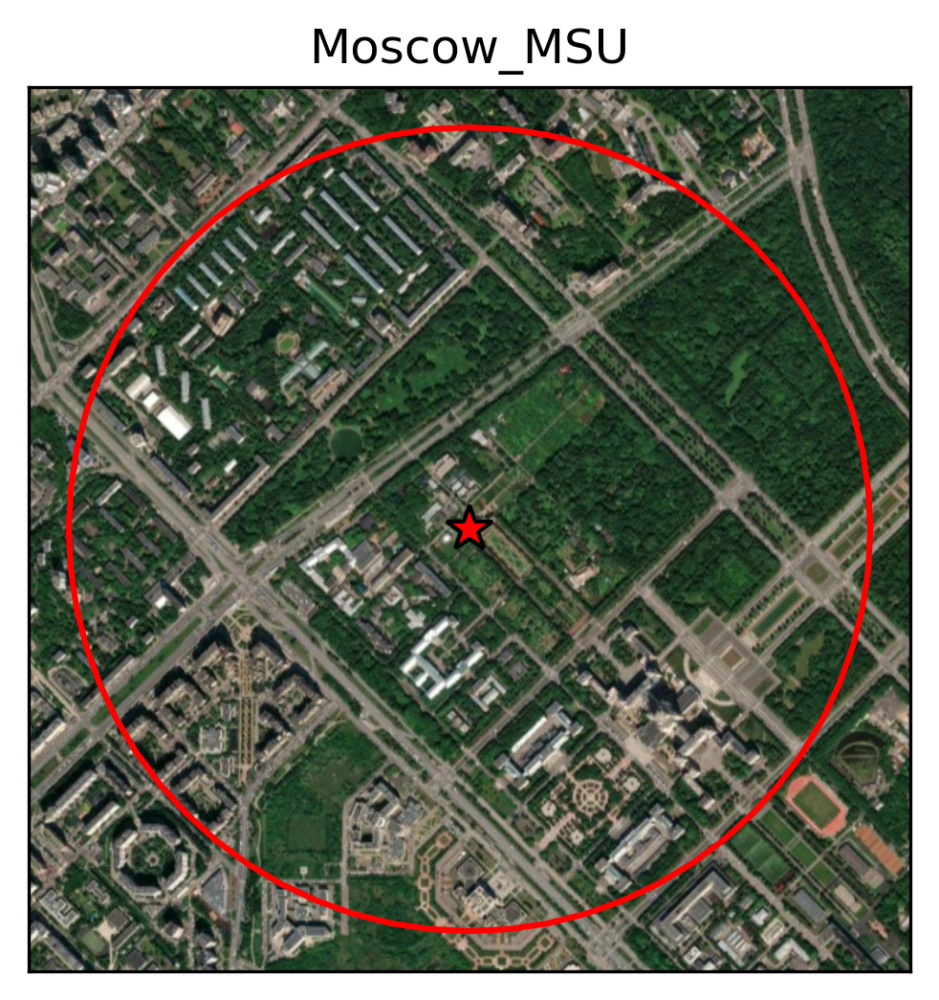

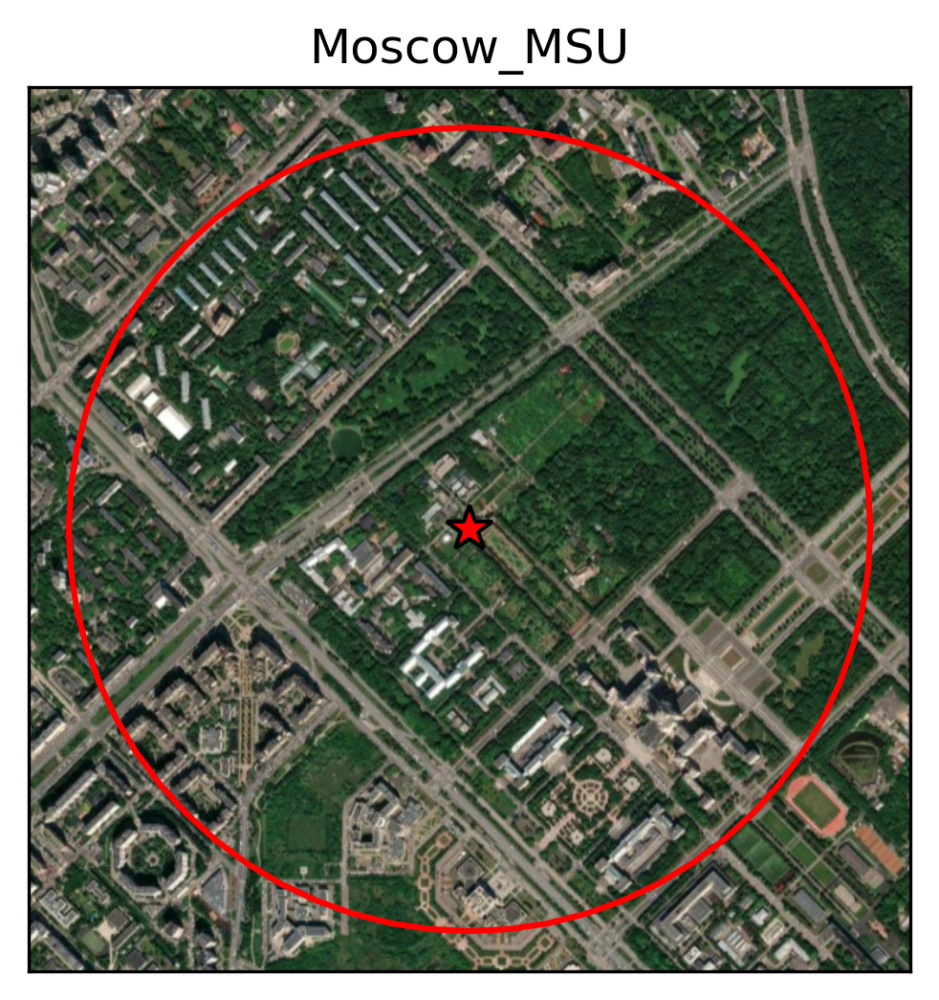

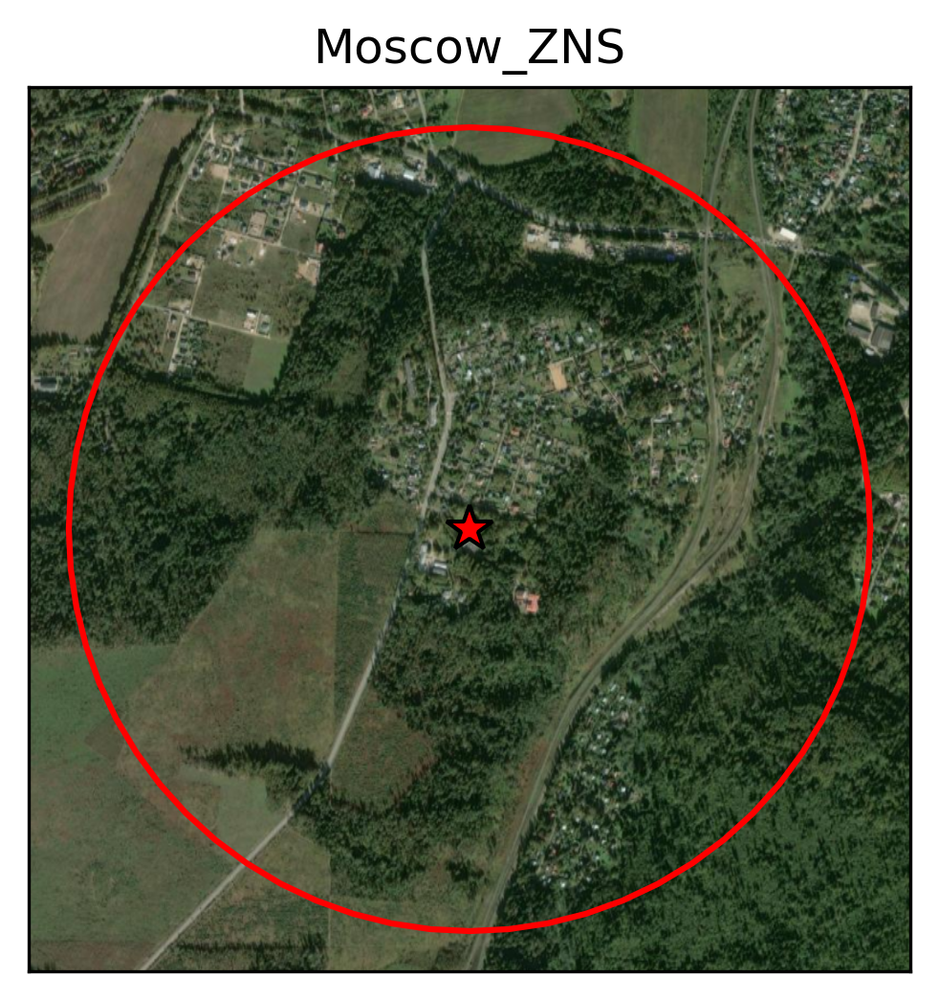

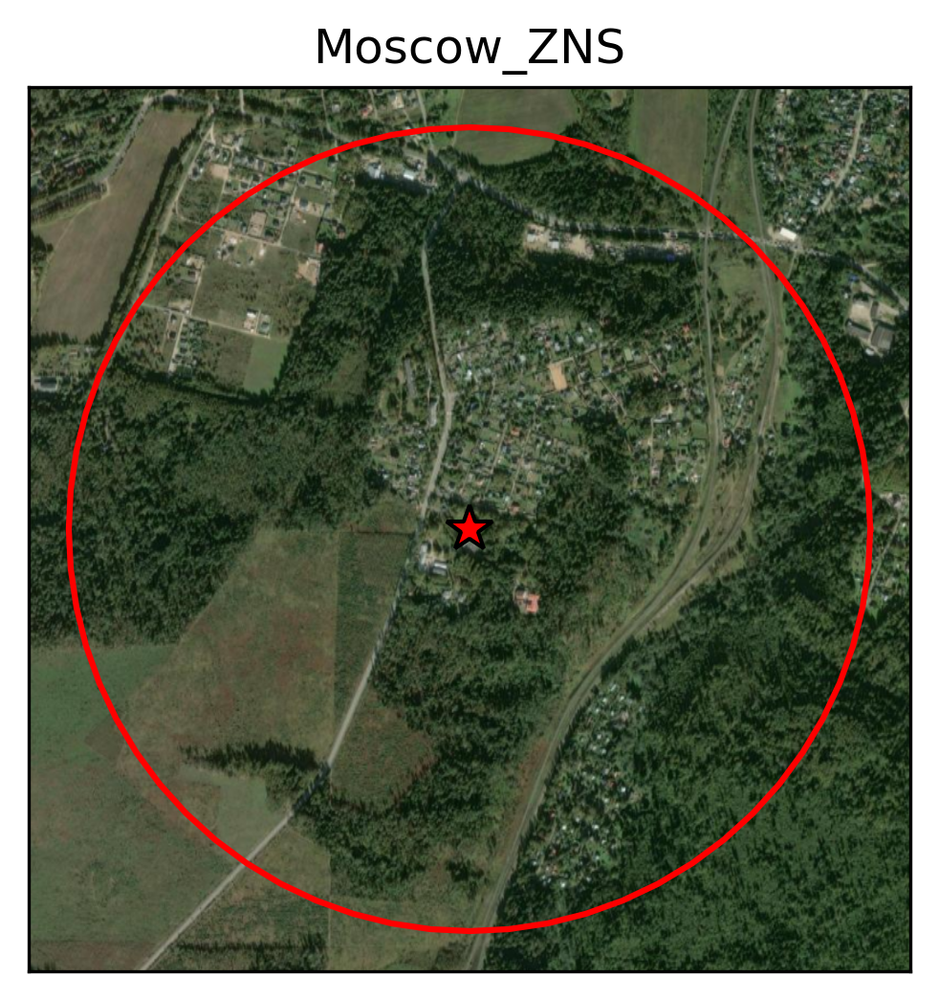

...

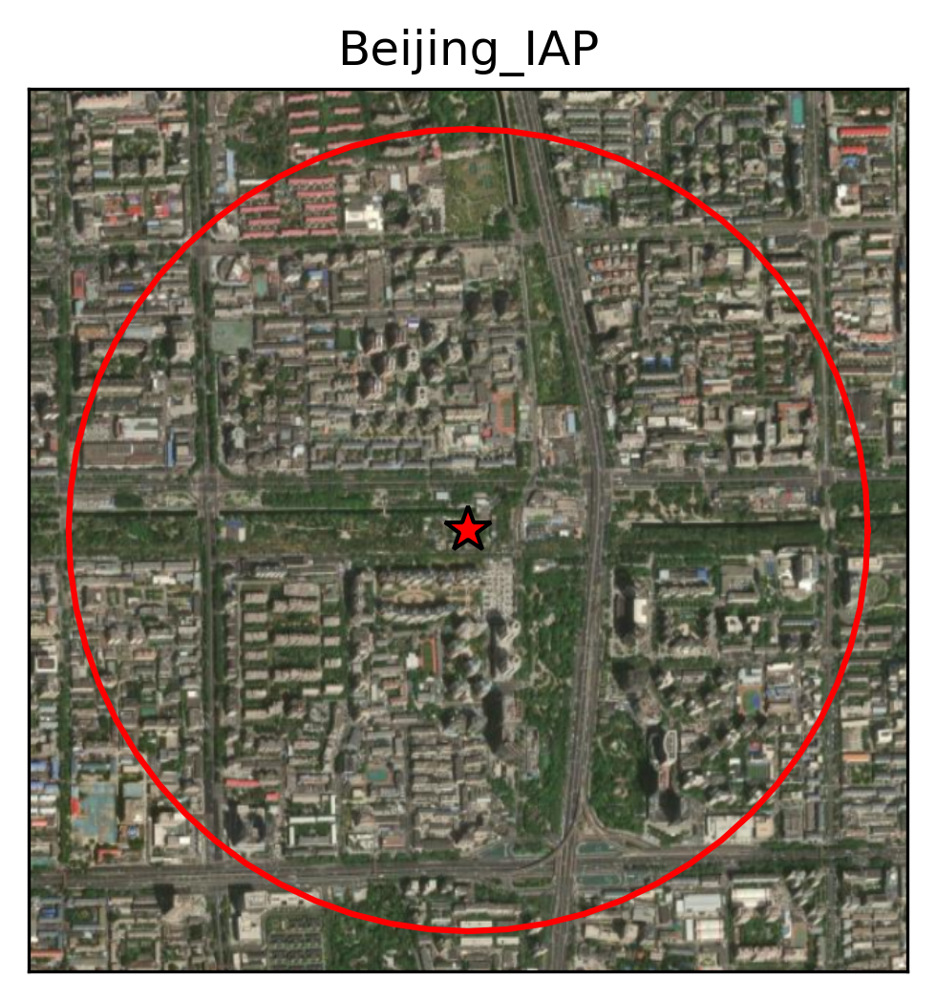

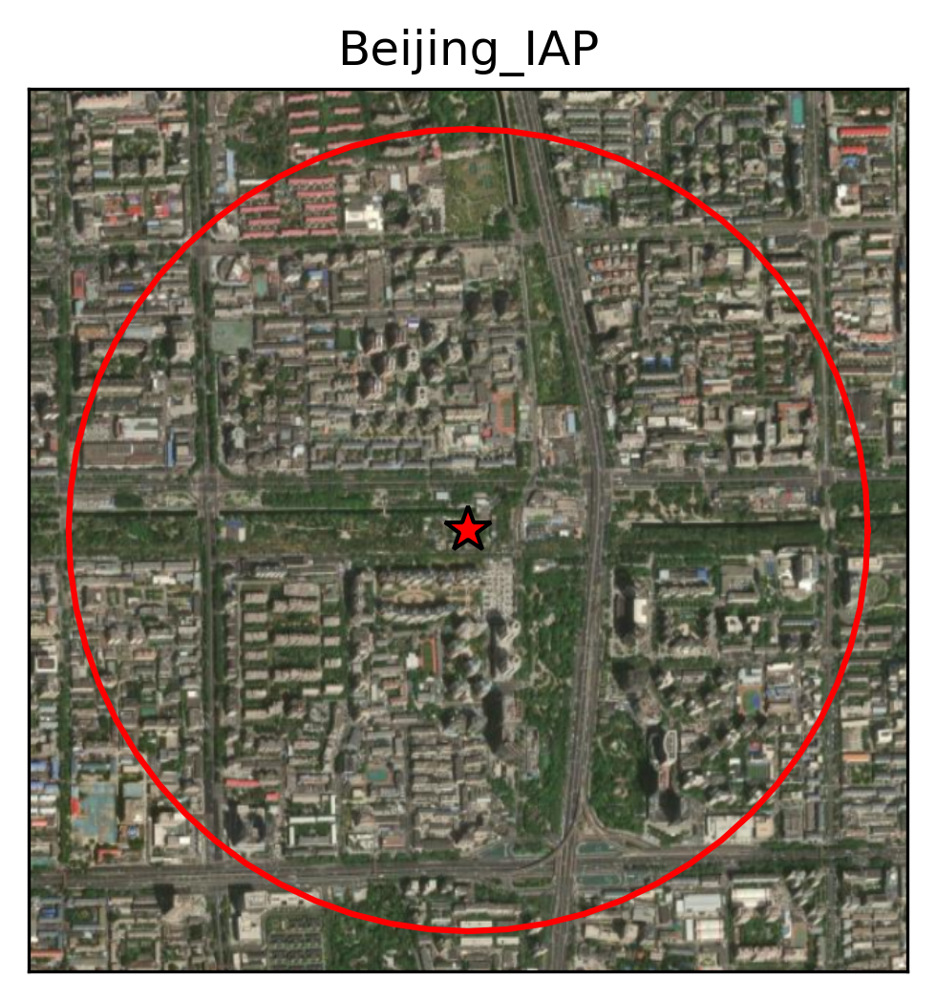

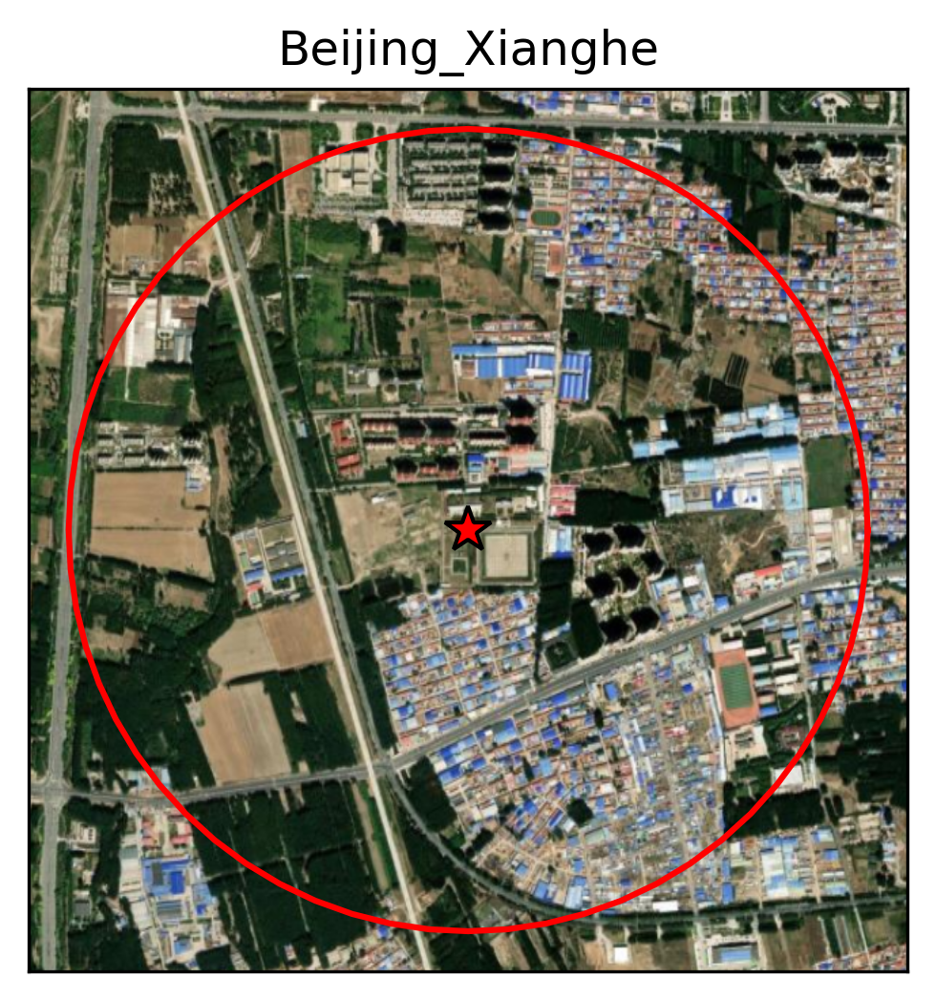

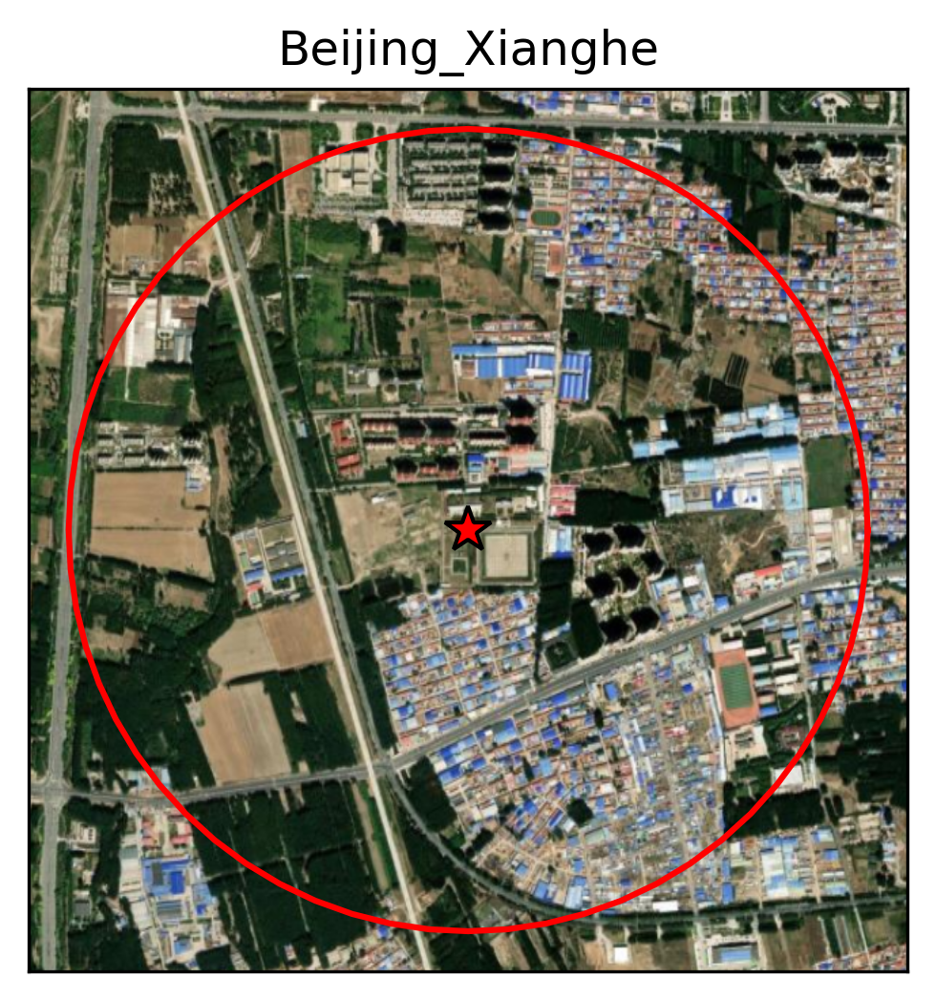

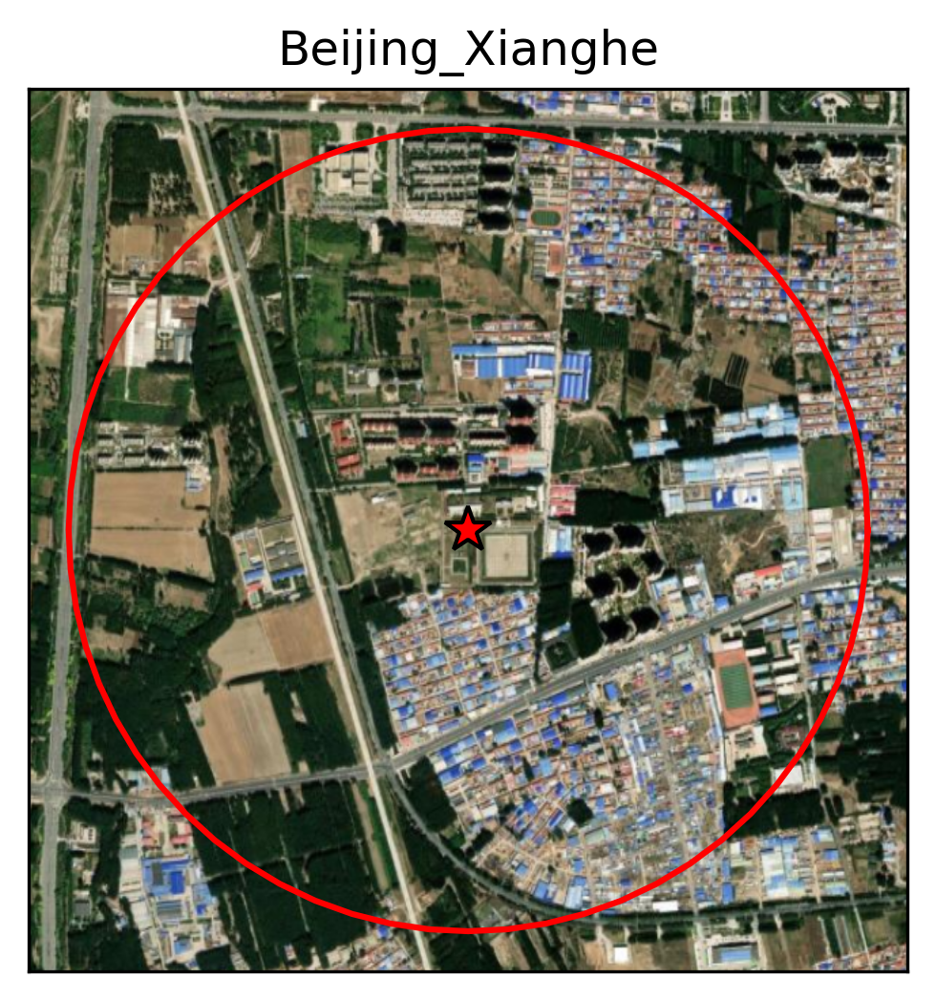

In [13]:
all_R = [500, 1000]

pics_dir = 'pics_site_images/'             
os.makedirs (pics_dir, exist_ok=True)

#sites_df['impervious_area_fraction_R%dm'%R] = np.nan
#sites_df['uc_area_fraction%dm'%R] = np.nan

for i in sites_df.index:
    for key, raster_path in raster_paths.items():
        for R in all_R:

            if isinstance (raster_path, dict): raster_path = raster_path[sites_df['city_name'][i]]
            
            pol = point_buffer1(sites_df['latitude'][i], sites_df['longitude'][i], R) #'], crd[0], R)

            src = rasterio.open (raster_path)
            subarray, trs = rasterio.mask.mask(src, [pol], crop=True, filled=False)
            
            lons, lats = get_subarray_coords_rio (subarray.shape[subarray.ndim-2:], src, trs)
            if 'WorldCover' in raster_path:
                wc_isa = subarray == 50
                sites_df.loc[i,'impervious_area_fraction_R%dm'%R]  = np.sum(wc_isa) / np.sum(~np.isnan(wc_isa))
            elif 'CGLC' in raster_path:
                sites_df.loc[i,'uc_area_fraction_R%dm'%R]  = np.mean(subarray)/100
            elif 'LCZ' in raster_path:
                lcz_urb = subarray.copy().astype(float)
                lcz_rur = subarray.copy().astype(float)
                
                lcz_urb[lcz_urb > 10] = np.nan
                lcz_rur[lcz_rur <= 10] = np.nan

                sites_df.loc[i,'LCZ_urb_R%dm'%R]  = scipy.stats.mode(lcz_urb.flatten())[0]
                sites_df.loc[i,'LCZ_nat_R%dm'%R]  = scipy.stats.mode(lcz_rur.flatten())[0]
                
        if True:
            #x,y = 
            plt.figure(figsize = (4,4))
            #plt.pcolormesh (lons, lats, subarray[0], alpha=0.5)

            plt.plot (sites_df['longitude'][i], sites_df['latitude'][i], '*r', markeredgecolor = 'black', markersize = 12)
            plt.plot(*pol.exterior.xy, '-r')
            
            #plt.xlim([plt.xlim()[0] - 0.1*(plt.xlim()[1]-plt.xlim()[0]), plt.xlim()[1] + 0.1*(plt.xlim()[1]-plt.xlim()[0])])
            #plt.ylim([plt.ylim()[0] - 0.1*(plt.ylim()[1]-plt.ylim()[0]), plt.ylim()[1] + 0.1*(plt.ylim()[1]-plt.ylim()[0])])
            
            plt.xticks([])
            plt.yticks([])
            plt.title (sites_df['city_name'][i] + '_' + sites_df['site_name'][i])

            cx.add_basemap(plt.gca(), source = cx.providers.Esri.WorldImagery,  crs = 4326, attribution_size = 2, attribution = '') #, zoom = 17)
            
            plt.gca().set_aspect(1.0/np.cos(np.array(plt.ylim()).mean()*np.pi/180))
        
            plt.savefig(pics_dir + f'{sites_df['city_name'][i]}_{sites_df['site_name'][i]}_R{R}.png')

        # points = gpd.GeoSeries([Point(161, ir_lat_lim.mean()), Point(162, ir_lat_lim.mean())], crs=4326)  # Geographic WGS 84 - degrees
        # points = points.to_crs(32619)
        # distance_meters = points[0].distance(points[1])

        # scalebar = ScaleBar(distance_meters, length_fraction=0.25, location = 'lower left', pad = 0.2, border_pad = 0.5) #, units = "km", )
        # plt.gca().add_artist(scalebar)        

In [ ]:
sites_df

,city_name,site_name,longitude,latitude,time_belt,obs_levels,impervious_area_fraction_R250m,impervious_area_fraction_R500m,impervious_area_fraction_R1000m,uc_area_fraction_R250m,uc_area_fraction_R500m,uc_area_fraction_R1000m,LCZ_urb_R250m,LCZ_nat_R250m,LCZ_urb_R500m,LCZ_nat_R500m,LCZ_urb_R1000m,LCZ_nat_R1000m
0,Moscow,MSU,37.522814,55.707187,3,"2,11,19",0.267410,0.304803,0.437657,0.624643,0.565268,0.688384,5.0,NaN,5.0,NaN,5.0,NaN
1,Tomsk,IMCES,85.054185,56.474956,7,"30,40",0.334389,0.469168,0.378914,0.914286,0.835652,0.712516,5.0,NaN,5.0,NaN,5.0,NaN
2,Tomsk,Oblkom,84.957451,56.467183,7,30,0.785870,0.806477,0.738119,0.988214,0.985690,0.958553,2.0,NaN,2.0,NaN,5.0,NaN
3,Tomsk,BEK,85.101526,56.480872,7,30,0.013151,0.005773,0.012517,0.000000,0.021724,0.027232,NaN,12.0,NaN,11.0,NaN,11.0
4,Beijing,IAP,116.371285,39.974304,8,"8,16,47,80,140,200,280",0.505210,0.656841,0.762991,0.901429,0.888571,0.954602,4.0,NaN,4.0,NaN,4.0,NaN
5,Beijing,Xianghe,116.960451,39.753441,8,"32,80",0.539500,0.551960,0.487558,0.650909,0.652907,0.501183,6.0,NaN,6.0,NaN,6.0,NaN


In [14]:
sites_df.to_csv(metadata_path.replace('_basic', ''))